# ThermoTwin-FM demo

End-to-end walk-through: generate synthetic telemetry → train → evaluate → simulate → call the API.

Run from the repo root after installing with `pip install -e ".[dev,notebook]"`.

In [2]:
import os
from pathlib import Path
if Path.cwd().name == 'notebooks':
    os.chdir(Path.cwd().parent)
print('cwd:', Path.cwd())

cwd: /Users/crisstaylor/Desktop/files-4/project_01_thermotwin_fm


## 1. Generate a small synthetic telemetry dataset

In [2]:
from thermotwin.data.synthetic import SyntheticConfig, write_sample_dataset

paths = write_sample_dataset('data/sample', SyntheticConfig(n_racks=8, n_cooling_units=2, duration_days=10, seed=42))
print(paths)

{'telemetry': PosixPath('data/sample/telemetry.csv'), 'layout': PosixPath('data/sample/layout.csv')}


## 2. Inspect the data and build the layout graph

In [3]:
import pandas as pd
from thermotwin.data.ingest_m100 import load_and_prepare
from thermotwin.graphs.layout_graph import build_graph

telemetry = load_and_prepare('data/sample/telemetry.csv', cadence_minutes=5)
layout = pd.read_csv('data/sample/layout.csv')
print('Telemetry rows:', len(telemetry), '| racks:', telemetry['rack_id'].nunique())
display(telemetry.head(3))
graph = build_graph(layout)
print('Graph nodes:', graph.n_nodes, '| edges>0:', int((graph.adjacency > 0).sum() // 2))

Telemetry rows: 23040 | racks: 8


,timestamp,rack_id,cooling_unit_id,cpu_load,gpu_load,power_draw_kw,fan_speed_pct,coolant_supply_temp,ambient_temp,inlet_temp,outlet_temp,cpu_load_missing,gpu_load_missing,power_draw_kw_missing,fan_speed_pct_missing,coolant_supply_temp_missing,ambient_temp_missing,inlet_temp_missing,outlet_temp_missing
0,2024-01-01,rack_00,cu_00,0.492325,0.435074,8.495691,68.141340,18.027438,12.152359,22.505955,22.716984,0,0,0,0,0,0,0,0
1,2024-01-01,rack_01,cu_01,0.203864,0.166730,5.178998,36.908860,19.332231,12.152359,22.691018,22.357328,0,0,0,0,0,0,0,0
2,2024-01-01,rack_02,cu_00,0.571320,0.628072,10.264452,76.674726,17.996869,12.152359,22.346467,22.993342,0,0,0,0,0,0,0,0


Graph nodes: 8 | edges>0: 20


## 3. Train the forecaster

We call the same `train.main` the CLI uses.

In [4]:
from thermotwin.train import main as train_main
rc = train_main(['--base-config', 'configs/base.yaml',
                 '--data-config', 'configs/data_m100.yaml',
                 '--model-config', 'configs/model_graphfm.yaml'])
print('train rc:', rc)

01:12:47 [INFO] thermotwin.train: Preparing data and windows


01:12:47 [INFO] thermotwin.data.ingest_m100: Loaded 23040 rows across 8 racks, 2 CUs


01:12:58 [INFO] thermotwin.train: epoch=0 train_loss=0.0773 val_loss=2.8433


01:13:03 [INFO] thermotwin.train: epoch=1 train_loss=0.0399 val_loss=0.8550


01:13:09 [INFO] thermotwin.train: epoch=2 train_loss=0.0367 val_loss=0.6426


01:13:15 [INFO] thermotwin.train: epoch=3 train_loss=0.0362 val_loss=0.4401


... (4 outputs left out)

01:13:46 [INFO] thermotwin.train: epoch=8 train_loss=0.0354 val_loss=0.0500


01:13:51 [INFO] thermotwin.train: epoch=9 train_loss=0.0353 val_loss=0.1029


01:13:52 [INFO] thermotwin.train: Saved model + manifest + history to artifacts


train rc: 0


## 4. Evaluate and plot per-horizon error

01:13:53 [INFO] matplotlib.font_manager: Failed to extract font properties from /usr/share/fonts/truetype/noto/NotoColorEmoji.ttf: Can not load face (unknown file format; error code 0x2)


01:13:53 [INFO] matplotlib.font_manager: generated new fontManager


01:13:54 [INFO] thermotwin.data.ingest_m100: Loaded 23040 rows across 8 racks, 2 CUs


01:13:54 [INFO] thermotwin.evaluate: Evaluation complete: MAE=0.400 RMSE=0.530 (naive MAE=0.339)


Model  MAE=0.400  RMSE=0.530
Naive  MAE=0.339  RMSE=0.465
Raw 90% coverage: 0.439
Conformal 90% coverage: 0.78


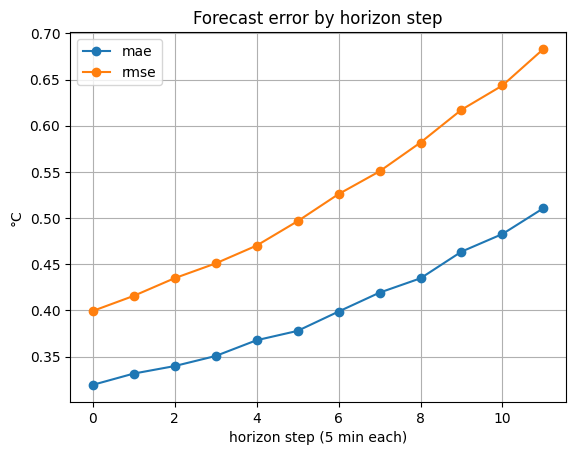

In [5]:
import json, pandas as pd, matplotlib.pyplot as plt

from thermotwin.evaluate import main as evaluate_main
evaluate_main(['--base-config', 'configs/base.yaml',
               '--data-config', 'configs/data_m100.yaml',
               '--model-config', 'configs/model_graphfm.yaml'])

report = json.load(open('artifacts/eval_report.json'))
print('Model  MAE={:.3f}  RMSE={:.3f}'.format(report['point_metrics']['mae'], report['point_metrics']['rmse']))
print('Naive  MAE={:.3f}  RMSE={:.3f}'.format(report['baseline_naive_last']['mae'], report['baseline_naive_last']['rmse']))
print('Raw 90% coverage:', round(report['calibration_raw']['empirical_coverage'], 3))
print('Conformal 90% coverage:', round(report['calibration_conformal']['empirical_coverage'], 3))

per_h = pd.DataFrame(report['per_horizon'])
per_h.plot(x='horizon_step', y=['mae', 'rmse'], marker='o', title='Forecast error by horizon step')
plt.grid(True); plt.xlabel('horizon step (5 min each)'); plt.ylabel('°C'); plt.show()

## 5. What-if simulation

In [6]:
from thermotwin.simulate import main as simulate_main
simulate_main(['--base-config', 'configs/base.yaml',
               '--data-config', 'configs/data_m100.yaml',
               '--model-config', 'configs/model_graphfm.yaml'])

ranking = pd.read_csv('artifacts/simulation_ranking.csv')
display(ranking)

01:13:54 [INFO] thermotwin.data.ingest_m100: Loaded 23040 rows across 8 racks, 2 CUs


01:13:54 [INFO] thermotwin.simulate: Wrote artifacts/simulation_report.json and simulation_ranking.csv


,scenario,max_predicted_inlet,max_q_high_inlet,risk_score,energy_proxy_mean_inlet,rank
0,lower_setpoint_2C,20.073652,20.357860,0.0,20.039161,1
1,load_spike_20pct,20.099776,20.410009,0.0,20.063836,2
2,baseline,20.100880,20.412339,0.0,20.065005,3
3,fan_boost,20.167503,20.489517,0.0,20.133167,4
4,raise_setpoint_2C,20.322522,20.711137,0.0,20.290846,5
5,cooling_degrade,20.696761,21.219529,0.0,20.655650,6


## 6. Call the API in-process

In [7]:
from fastapi.testclient import TestClient
from thermotwin.api import create_app
from thermotwin.data.ingest_m100 import load_and_prepare
from thermotwin.features.resample_and_window import build_windows, time_block_split
from thermotwin.utils.io import load_json

app = create_app('artifacts')
client = TestClient(app)
health = client.get('/health').json()
print('Service health:', {k: health[k] for k in ('status', 'n_racks', 'context_steps', 'horizon_steps')})

manifest = load_json('artifacts/model_manifest.json')
telemetry = load_and_prepare('data/sample/telemetry.csv', cadence_minutes=5)
splits = time_block_split(telemetry, val_fraction=0.15, test_fraction=0.15)
win = build_windows(splits['test'],
                    features=manifest['feature_order'],
                    targets=manifest['target_order'],
                    controls=manifest['control_order'],
                    context_steps=int(manifest['context_steps']),
                    horizon_steps=int(manifest['horizon_steps']),
                    stride=1)
racks = sorted(telemetry['rack_id'].unique())
rack_id = racks[int(win.entity[0])]

payload = {'rack_id': rack_id,
           'context': win.context[0].tolist(),
           'controls': win.controls[0].tolist()}
r = client.post('/forecast', json=payload).json()
print('Forecast for', rack_id, ': first horizon median °C =', [round(x, 2) for x in r['median'][0]])

01:13:55 [INFO] httpx: HTTP Request: GET http://testserver/health "HTTP/1.1 200 OK"


01:13:55 [INFO] thermotwin.data.ingest_m100: Loaded 23040 rows across 8 racks, 2 CUs


Service health: {'status': 'ok', 'n_racks': 8, 'context_steps': 24, 'horizon_steps': 12}


01:13:55 [INFO] httpx: HTTP Request: POST http://testserver/forecast "HTTP/1.1 200 OK"


Forecast for rack_00 : first horizon median °C = [20.06, 25.13]
